## Cost function

it helps to the prediction line by removing errors from data

types of cost function

1) Regression cost Analysis

  - MSE ( Mean Square Error )

  - RMSE ( Root Meab Square Error )

  - MAE ( Mean Absolute Error )

  - R2 Accuracy



2) Classification cost Analysis

   a) Binary classification cost function

   b) Multi-class classification cost function

      - Binary Cross Entropy
      
      - Log Loss Function



### Regression Cost Function

#### i) MSE  

- repeatdely draws line to minimise errors

- uses

MSE = 1/n sum{(yi - y'i)^2}

yi = input

y'i = output

advantages ..

diadvantages ..

#### i) MAE

- repeatdely draws line to minimise errors
- used mod

MAE = 1/n sum{|yi - y'i|}

yi = input

y'i = output

advantages ..

diadvantages ..

addd infor for more

## Regularization Techniques

improves a model by removing unusanble data

acts as feature selection

reduces overfitting

what overfitting?
( ans it)

Regularization Techniques 

1) Ridge Regularization / L2

2) Lasso Regularizarion / L1

### Lasso Regularizarion / L1 Technique

- does work of feature selection

- adds lambda and w to MSE in formula

loss =  sum of square residual

lamda = penalty

q = slope of the curve





### Ridge Regularization / L2 technique

- reduces overfitting value





### Creating a simple Linear Regression Model without Lasso or Ridge

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [4]:
dataset = pd.read_csv(r"C:\Users\junai\Desktop\coding\ML\house_prices_data.csv")
dataset.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price
0,4,2.5,3952,1686,3.0,0,2,3,3154,798,1936,0,1045632
1,5,3.5,1414,9476,2.0,0,1,5,1003,411,1978,0,488642
2,3,2.0,2071,5811,2.5,0,2,4,1716,355,1991,0,661199
3,5,3.7,1808,12939,3.0,0,0,5,1231,577,1917,0,515048
4,5,2.2,3247,9954,1.0,0,3,3,1964,1283,1997,0,1027363


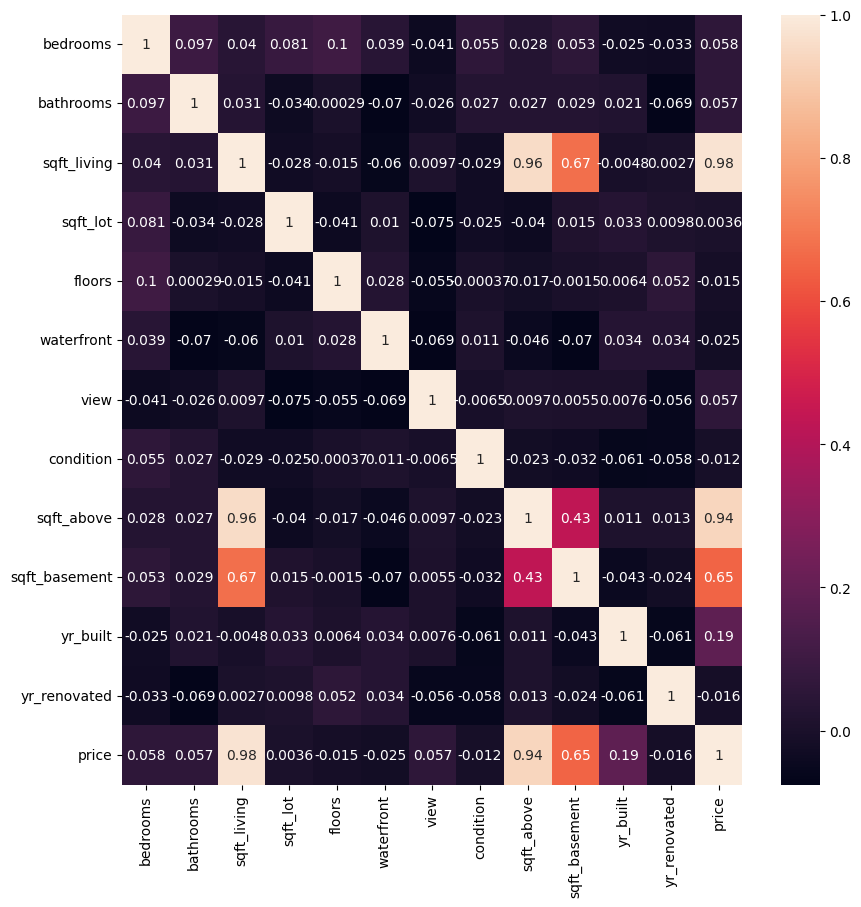

In [7]:
# can linear regression be used?
# we need to find the correation matrix
plt.figure(figsize=(10, 10))
sns.heatmap(dataset.corr(), annot=True)
plt.show()

In [8]:
# its not linear
# we need to scale the data for that we need to seperate input and output data i.e independent and dependent variables
X = dataset.iloc[:, :-1]  # all columns except the last one
Y = dataset["price"]  # last column

In [10]:
# now scaling data 
# what scaling does is it brings all the values to a common scale
sc = StandardScaler()
sc.fit(X)
X = pd.DataFrame(sc.transform(X), columns=X.columns)


In [12]:
# train test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [13]:
# creating a linear regression model
from sklearn.linear_model import LinearRegression , Lasso, Ridge

In [14]:
lr = LinearRegression()
lr.fit(X_train, Y_train)

LinearRegression()

In [23]:
lr.score(X_test, Y_test)*100

99.3482684440668

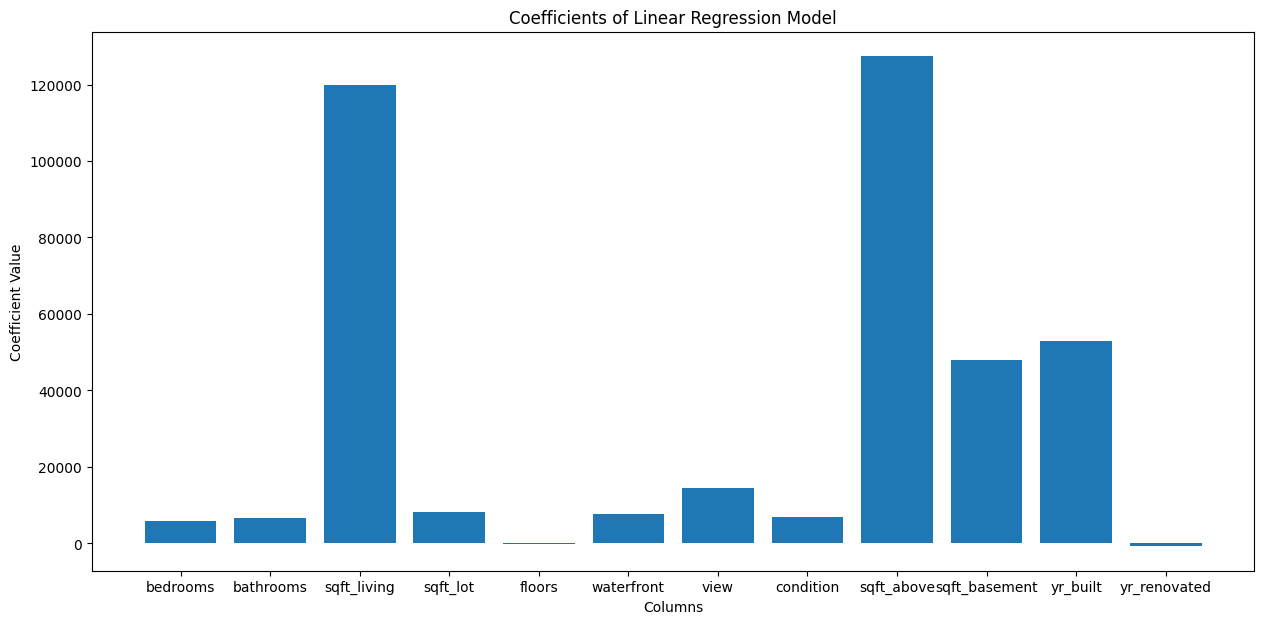

In [20]:
# now represting the constant and coefficients value of model graphically
plt.figure(figsize=(15, 7))
plt.bar(X.columns, lr.coef_)
plt.title("Coefficients of Linear Regression Model")
plt.xlabel("Columns")
plt.ylabel("Coefficient Value")
plt.show()

### Now using Lasso

In [26]:
# Lasso is used for feature selection
la = Lasso(alpha=0.01) # alpha is the regularization parameter i.e panelty corner
la.fit(X_train, Y_train)
la.score(X_test, Y_test)*100

99.34826829891055

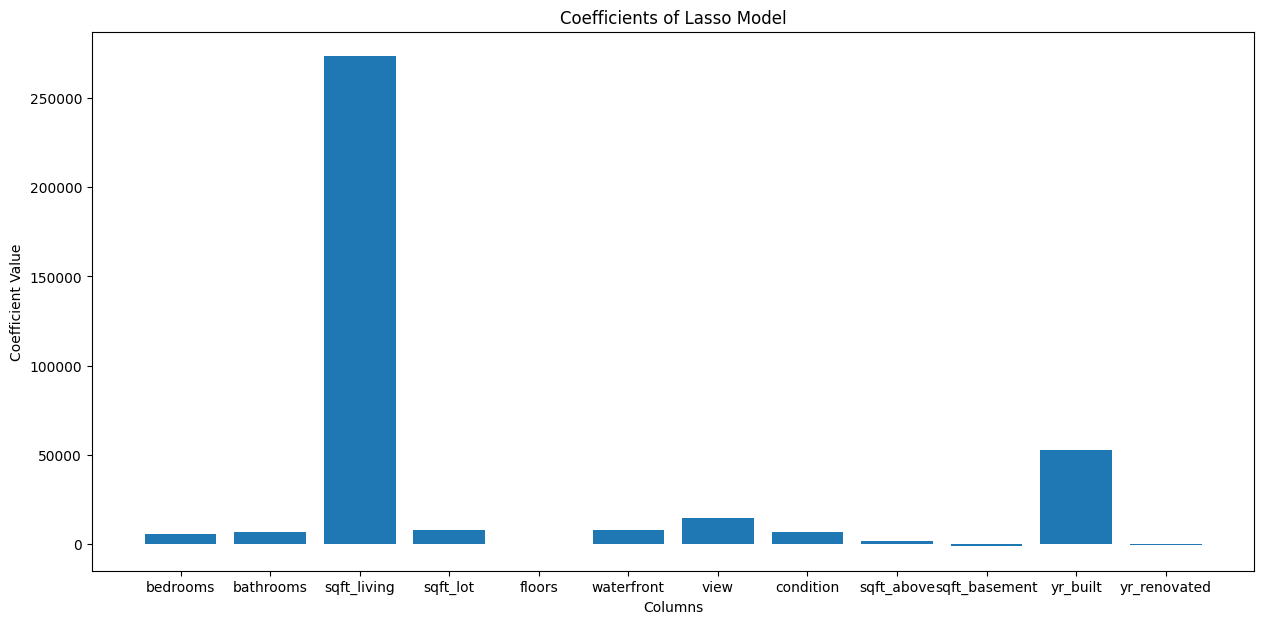

In [27]:
# now represting the constant and coefficients value of model graphically for lasso
plt.figure(figsize=(15, 7))
plt.bar(X.columns, la.coef_)
plt.title("Coefficients of Lasso Model")
plt.xlabel("Columns")
plt.ylabel("Coefficient Value")
plt.show()

### Now using Ridge

In [28]:
# Ridge is used for regularization
ri = Ridge(alpha=0.01)  # alpha is the regularization parameter
ri.fit(X_train, Y_train)
ri.score(X_test, Y_test)*100


99.34826628151767

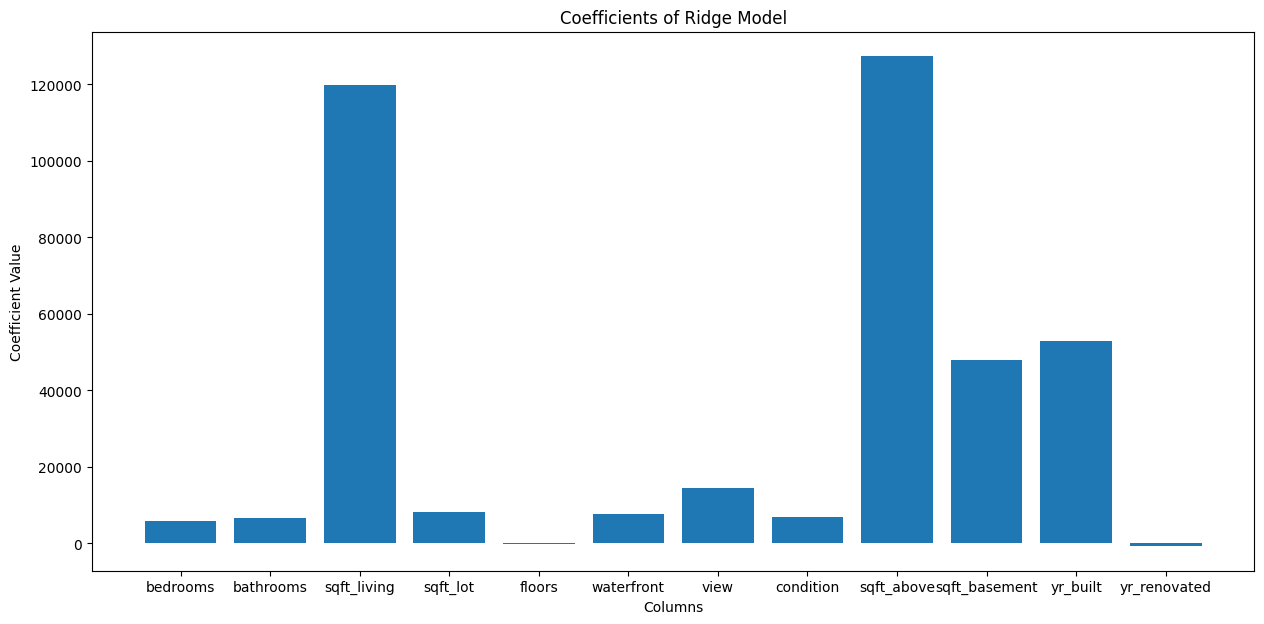

In [31]:
# now represting the constant and coefficients value of model graphically for Ridge
plt.figure(figsize=(15, 7))
plt.bar(X.columns, ri.coef_)
plt.title("Coefficients of Ridge Model")
plt.xlabel("Columns")
plt.ylabel("Coefficient Value")
plt.show()

In [36]:
# Now comparing the three models
from sklearn.metrics import   mean_absolute_error , mean_squared_error
import numpy as np

In [39]:
print("Linear Regression Model")
print("MSE = " , mean_squared_error(lr.predict(X_test), Y_test))
print("MAE = ",mean_absolute_error(lr.predict(X_test), Y_test))
print("R2 Score = ", np.sqrt(mean_squared_error(lr.predict(X_test), Y_test)))

print("\nLasso Model")
print("MSE = " , mean_squared_error(la.predict(X_test), Y_test))
print("MAE = ",mean_absolute_error(la.predict(X_test), Y_test)) 
print("R2 Score = ", np.sqrt(mean_squared_error(la.predict(X_test), Y_test)))

print("\nRidge Model")
print("MSE = " , mean_squared_error(ri.predict(X_test), Y_test))
print("MAE = ",mean_absolute_error(ri.predict(X_test), Y_test))
print("R2 Score = ", np.sqrt(mean_squared_error(ri.predict(X_test), Y_test)))
# Now we can see that the Lasso model is giving the best results

Linear Regression Model
MSE =  497649687.6560789
MAE =  17054.956265457935
R2 Score =  22308.063287880435

Lasso Model
MSE =  497649798.49459326
MAE =  17054.952946213743
R2 Score =  22308.065772150512

Ridge Model
MSE =  497651338.9370303
MAE =  17054.67904321314
R2 Score =  22308.100298703837


In [41]:
# comaring coefficients of all three models
df = pd.DataFrame({
    "Columns": X.columns,
    "Linear Regression Coefficients": lr.coef_,
    "Lasso Coefficients": la.coef_,
    "Ridge Coefficients": ri.coef_
})
df

,Columns,Linear Regression Coefficients,Lasso Coefficients,Ridge Coefficients
0,bedrooms,5821.743426,5821.734036,5821.713479
1,bathrooms,6603.324429,6603.313646,6603.183871
2,sqft_living,119786.832451,273468.130417,119785.389539
3,sqft_lot,8106.145196,8106.134747,8105.859191
4,floors,-139.068288,-139.057621,-139.063268
5,waterfront,7586.517651,7586.505764,7586.062106
6,view,14529.500716,14529.488662,14529.051380
7,condition,6773.835323,6773.825376,6773.479330
8,sqft_above,127432.301427,1509.448004,127430.354307
9,sqft_basement,48026.228229,-1162.673998,48026.704736


In [42]:
# normaly Lasso and  Ridge makes the linear regression model better
# but in this case we can see that the all are same since the Accuracy of linear regression model is already good
# so we can use any of the three models
# but if it was not the case then we would have used Lasso or Ridge model, because they are better in terms of feature selection and regularization respectively